# 8장. 작은 데이터 분석 프로젝트 완성하기

이 노트북은 데이터 점검, 전처리, 병합 검증, 완료 주문 기준 집계, 시각화, 보고서 작성을 하나의 재현 가능한 프로젝트로 연결합니다.


## 학습 목표

- 원본 데이터를 보존하며 전처리합니다.
- 주요 키 중복과 외래키 미매칭을 확인합니다.
- `validate`와 `indicator`를 사용한 병합 검증 원리를 확인합니다.
- 취소·환불 주문을 제외하고 완료 주문 기준 매출을 계산합니다.
- 고객 이름을 노출하지 않는 익명화 결과를 만듭니다.
- 결과 CSV, 그래프, Markdown 보고서를 재현 가능하게 저장합니다.


## 1. 프로젝트 루트와 출력 폴더 설정

VS Code에서 현재 작업 폴더가 프로젝트 루트 또는 `notebooks`일 수 있으므로 상위 폴더를 탐색합니다.


In [17]:
from pathlib import Path
import sys

import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / 'requirements.txt').exists() and (candidate / 'scripts').exists():
            return candidate
    raise FileNotFoundError('프로젝트 루트 폴더를 찾을 수 없습니다.')


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
FIGURE_DIR = REPORT_DIR / 'figures'

for path in [PROCESSED_DIR, REPORT_DIR, FIGURE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('Python 실행 파일:', sys.executable)
print('프로젝트 루트:', PROJECT_ROOT)
print('원본 데이터 폴더:', RAW_DIR)
print('보고서 폴더:', REPORT_DIR)


Python 실행 파일: c:\dev\llm-data-analysis-study\.venv\Scripts\python.exe
프로젝트 루트: C:\dev\llm-data-analysis-study
원본 데이터 폴더: C:\dev\llm-data-analysis-study\data\raw
보고서 폴더: C:\dev\llm-data-analysis-study\reports


## 2. 프로젝트 함수 불러오기

중간 프로젝트의 공통 로직은 `src/` 모듈에 정리되어 있습니다. Notebook과 일괄 실행 스크립트가 같은 함수를 사용하므로 계산 기준이 어긋나는 문제를 줄일 수 있습니다.


In [18]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    compare_shapes,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)
from src.midterm_project import (
    build_analysis_tables,
    build_interpretation_notes,
    build_key_duplicate_checks,
    build_midterm_report,
    create_project_figures,
    run_midterm_project,
    save_project_tables,
    summarize_datasets,
)


## 3. 원본 데이터 확인

파일이 없다면 프로젝트 루트에서 `python scripts/generate_sample_data.py`를 먼저 실행합니다.


In [19]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f'\n===== {name} =====')
    print('shape:', df.shape)
    print('columns:', df.columns.tolist())
    print('missing values:', int(df.isna().sum().sum()))
    print('duplicated rows:', int(df.duplicated().sum()))


,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


## 4. 원본을 보존하며 전처리

`preprocess_sales_data()`는 원본 DataFrame을 직접 수정하지 않고 전처리된 복사본을 반환합니다.


In [20]:
processed_data = preprocess_sales_data(raw_data)
processed_paths = save_processed_data(processed_data, PROCESSED_DIR)

preprocessing_comparison = compare_shapes(raw_data, processed_data)
display(preprocessing_comparison)

for path in processed_paths:
    print(path, 'OK' if path.exists() else 'MISSING')


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,order_items,764,5,764,6
2,orders,300,5,300,7
3,products,100,4,100,4


C:\dev\llm-data-analysis-study\data\processed\customers_clean.csv OK
C:\dev\llm-data-analysis-study\data\processed\products_clean.csv OK
C:\dev\llm-data-analysis-study\data\processed\orders_clean.csv OK
C:\dev\llm-data-analysis-study\data\processed\order_items_clean.csv OK


## 5. 키 중복과 관계 점검

전체 행 중복뿐 아니라 고객·상품·주문·주문 상세의 식별 키 중복을 확인합니다. 외래키가 기준 테이블에 존재하지 않는 행도 확인합니다.


In [21]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data)

display(key_duplicate_checks)
display(relationship_checks)


,dataset,key,duplicate_count
0,customers,customer_id,0
1,products,product_id,0
2,orders,order_id,0
3,order_items,order_item_id,0


,check,invalid_count
0,orders.customer_id exists in customers.custome...,0
1,order_items.order_id exists in orders.order_id,0
2,order_items.product_id exists in products.prod...,0


In [22]:
import pandas as pd

KEYS = {
    "customers": "customer_id",
    "products": "product_id",
    "orders": "order_id",
    "order_items": "order_item_id",
}

PLACEHOLDERS = ["", "N/A", "NA", "null", "None", "unknown"]


def build_quality_summary(data: dict[str, pd.DataFrame], keys: dict[str, str]) -> pd.DataFrame:
    """테이블별 결측/중복 통합 요약"""
    rows = []
    for name, df in data.items():
        total_cells = df.shape[0] * df.shape[1]
        missing_cells = int(df.isna().sum().sum())

        obj_cols = df.select_dtypes(include=["object", "string"]).columns
        placeholder_cells = sum(
            int(df[c].astype(str).str.strip().isin(PLACEHOLDERS).sum()) for c in obj_cols
        )

        key = keys.get(name)
        rows.append({
            "dataset": name,
            "rows": len(df),
            "columns": df.shape[1],
            "missing_cells": missing_cells,
            "missing_ratio(%)": round(missing_cells / total_cells * 100, 2) if total_cells else 0,
            "rows_with_missing": int(df.isna().any(axis=1).sum()),
            "placeholder_cells": placeholder_cells,
            "duplicate_rows": int(df.duplicated().sum()),
            "key": key,
            "duplicate_keys": int(df[key].duplicated().sum()) if key in df.columns else None,
        })
    return pd.DataFrame(rows)


def build_missing_detail(data: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """컬럼별 결측 상세"""
    rows = []
    for name, df in data.items():
        for col in df.columns:
            n = int(df[col].isna().sum())
            rows.append({
                "dataset": name,
                "column": col,
                "dtype": str(df[col].dtype),
                "missing_count": n,
                "missing_ratio(%)": round(n / len(df) * 100, 2) if len(df) else 0,
            })
    return pd.DataFrame(rows)


def run_quality_check(data: dict[str, pd.DataFrame], keys: dict[str, str]) -> dict:
    summary = build_quality_summary(data, keys)
    detail = build_missing_detail(data)

    print("=" * 50)
    print("데이터 품질 점검 요약 (결측 / 중복)")
    print("=" * 50)
    display(summary)

    total_missing = summary["missing_cells"].sum()
    total_placeholder = summary["placeholder_cells"].sum()
    total_dup_rows = summary["duplicate_rows"].sum()
    total_dup_keys = summary["duplicate_keys"].fillna(0).sum()

    print(f"\n결측 셀        : {total_missing}건 " + ("✅" if total_missing == 0 else "⚠️"))
    print(f"placeholder 값 : {total_placeholder}건 " + ("✅" if total_placeholder == 0 else "⚠️"))
    print(f"전체 행 중복   : {total_dup_rows}건 " + ("✅" if total_dup_rows == 0 else "⚠️"))
    print(f"식별 키 중복   : {int(total_dup_keys)}건 " + ("✅" if total_dup_keys == 0 else "⚠️"))

    if total_missing > 0:
        print("\n[결측이 있는 컬럼]")
        display(detail[detail["missing_count"] > 0])

    if total_dup_rows > 0 or total_dup_keys > 0:
        print("\n[중복이 있는 테이블]")
        display(summary.loc[
            (summary["duplicate_rows"] > 0) | (summary["duplicate_keys"].fillna(0) > 0),
            ["dataset", "duplicate_rows", "key", "duplicate_keys"],
        ])

    return {"summary": summary, "missing_detail": detail}


quality_report = run_quality_check(processed_data, KEYS)

데이터 품질 점검 요약 (결측 / 중복)


,dataset,rows,columns,missing_cells,missing_ratio(%),rows_with_missing,placeholder_cells,duplicate_rows,key,duplicate_keys
0,customers,150,6,0,0.0,0,0,0,customer_id,0
1,products,100,4,0,0.0,0,0,0,product_id,0
2,orders,300,7,0,0.0,0,0,0,order_id,0
3,order_items,764,6,0,0.0,0,0,0,order_item_id,0



결측 셀        : 0건 ✅
placeholder 값 : 0건 ✅
전체 행 중복   : 0건 ✅
식별 키 중복   : 0건 ✅


## 6. 안전한 병합과 완료 주문 기준 집계

`build_analysis_tables()`는 다음 기준을 적용합니다.

- 주문 상세와 주문: `many_to_one`
- 완료 주문만 매출 집계에 포함
- 주문 상세와 상품: `many_to_one`
- 고객 집계와 고객 속성: `one_to_one`
- 병합 전후 행 수와 미매칭 건수 기록


In [23]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables['merge_checks'])
display(analysis_tables['amount_scope_summary'])


,merge,before_rows,after_rows,row_count_preserved,unmatched_count
0,order_id → orders,764,764,True,0
1,product_id → products,474,474,True,0
2,customer_id → customers,100,100,True,0


,scope,amount,detail_rows
0,all_order_items,255610000.0,764
1,completed_order_items,148990000.0,474
2,excluded_cancelled_or_refunded,106620000.0,290


## 7. 주요 결과 확인

아래 매출표는 모두 완료 주문 기준입니다. 주문 상태별 요약표는 전체 주문을 대상으로 합니다.


In [24]:
category_sales = analysis_tables['category_sales']
monthly_sales = analysis_tables['monthly_sales']
customer_sales = analysis_tables['customer_sales']
order_status_summary = analysis_tables['order_status_summary']

display(category_sales)
display(monthly_sales)
display(
    customer_sales[
        ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
    ].head(10)
)
display(order_status_summary)


,category,total_quantity,total_sales,sales_ratio
3,스포츠,295,31743000,21.31
5,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
1,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
0,도서,149,16389000,11.00
6,패션,111,10587000,7.11


,order_month,total_sales,order_count,avg_order_value
0,2025-09,2650000,5,530000.0
1,2025-10,14566000,16,910375.0
2,2025-11,11403000,14,814500.0
3,2025-12,20963000,22,952864.0
4,2026-01,16416000,19,864000.0
5,2026-02,3861000,6,643500.0
6,2026-03,19010000,25,760400.0
7,2026-04,10490000,16,655625.0
8,2026-05,14900000,18,827778.0
9,2026-06,14244000,17,837882.0


,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 117,성남,5,4100000,820000.0
1,Customer 102,고양,4,3996000,999000.0
2,Customer 83,수원,4,3880000,970000.0
3,Customer 30,서울,5,3590000,718000.0
4,Customer 40,서울,4,3523000,880750.0
5,Customer 20,인천,2,3191000,1595500.0
6,Customer 3,성남,2,3178000,1589000.0
7,Customer 111,광주,3,3153000,1051000.0
8,Customer 66,서울,4,3093000,773250.0
9,Customer 147,부산,2,2990000,1495000.0


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


In [25]:
print("processed_data" in globals())

True


In [26]:
orders = processed_data["orders"]
order_items = processed_data["order_items"]
products = processed_data["products"]

completed_items = (
    order_items
    .merge(orders[["order_id", "customer_id", "order_date", "order_status", "order_month"]],
           on="order_id", how="left")
    .merge(products[["product_id", "product_name", "category", "price"]],
           on="product_id", how="left")
)

completed_items = completed_items[completed_items["order_status"] == "completed"]

print(len(completed_items))                 # 474
print(completed_items["line_total"].sum())  # 148990000

474
148990000


In [27]:
price_qty = (completed_items.groupby(["product_id", "product_name", "category", "price"])
             .agg(total_quantity=("quantity", "sum"))
             .reset_index())

print("상품 수:", len(price_qty))
print("상관계수:", round(price_qty["price"].corr(price_qty["total_quantity"]), 3))

display(price_qty[["price", "total_quantity"]].describe().round(1))

cols = ["product_name", "category", "price", "total_quantity"]
display(price_qty.sort_values(["total_quantity", "product_name"], ascending=[False, True]).head(5)[cols])
display(price_qty.sort_values(["total_quantity", "product_name"], ascending=[True, True]).head(5)[cols])

상품 수: 98
상관계수: -0.239


,price,total_quantity
count,98.0,98.0
mean,110622.4,14.7
std,56502.1,8.0
min,5000.0,2.0
25%,67250.0,8.0
50%,112000.0,14.0
75%,161000.0,20.8
max,200000.0,35.0


,product_name,category,price,total_quantity
39,스포츠 상품 041,스포츠,163000,35
74,전자기기 상품 077,전자기기,71000,31
10,패션 상품 011,패션,115000,31
86,생활용품 상품 089,생활용품,103000,30
20,생활용품 상품 022,생활용품,112000,29


,product_name,category,price,total_quantity
33,스포츠 상품 035,스포츠,59000,2
18,패션 상품 019,패션,108000,2
7,스포츠 상품 008,스포츠,189000,3
73,전자기기 상품 075,전자기기,45000,3
27,패션 상품 029,패션,78000,3


## 8. 해석 메모와 결과 저장

관찰, 주의점, 다음 질문을 분리합니다. 고객 결과에는 실제 이름을 포함하지 않습니다.


In [28]:
interpretation_notes = build_interpretation_notes()
display(interpretation_notes)

saved_tables = save_project_tables(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
    REPORT_DIR,
)

for path in saved_tables:
    print(path.name, path.exists(), path.stat().st_size)


,analysis,observation,caution,next_question
0,카테고리별 완료 주문 매출,완료 주문 매출 비중이 높은 카테고리를 확인할 수 있습니다.,매출이 높은 이유가 판매 수량인지 단가인지 구분해야 합니다.,카테고리별 평균 판매 단가는 어떻게 다른가?
1,월별 완료 주문 매출,시간에 따른 완료 주문 매출의 증가와 감소를 확인할 수 있습니다.,프로모션이나 계절성이 원인이라고 단정할 수 없습니다.,주문 수와 평균 주문 금액 중 무엇이 변했는가?
2,고객별 완료 주문 구매 금액,완료 주문 구매 금액이 높은 고객군을 확인할 수 있습니다.,일회성 고액 구매와 반복 구매를 구분해야 합니다.,최근 구매일과 구매 빈도는 어떻게 다른가?
3,주문 상태별 주문 수,"완료, 취소, 환불 주문의 분포를 확인할 수 있습니다.",주문 상태의 정의와 처리 기준을 확인해야 합니다.,취소율과 환불률은 월별로 달라지는가?


ch08_dataset_summary.csv True 138
ch08_preprocessing_comparison.csv True 156
ch08_key_duplicate_checks.csv True 128
ch08_relationship_checks.csv True 184
ch08_merge_checks.csv True 187
ch08_amount_scope_summary.csv True 149
ch08_category_sales.csv True 254
ch08_monthly_sales.csv True 439
ch08_customer_sales.csv True 4333
ch08_order_status_summary.csv True 101
ch08_interpretation_notes.csv True 1036


## 9. 그래프 생성

그래프 제목에도 완료 주문 기준임을 표시합니다.


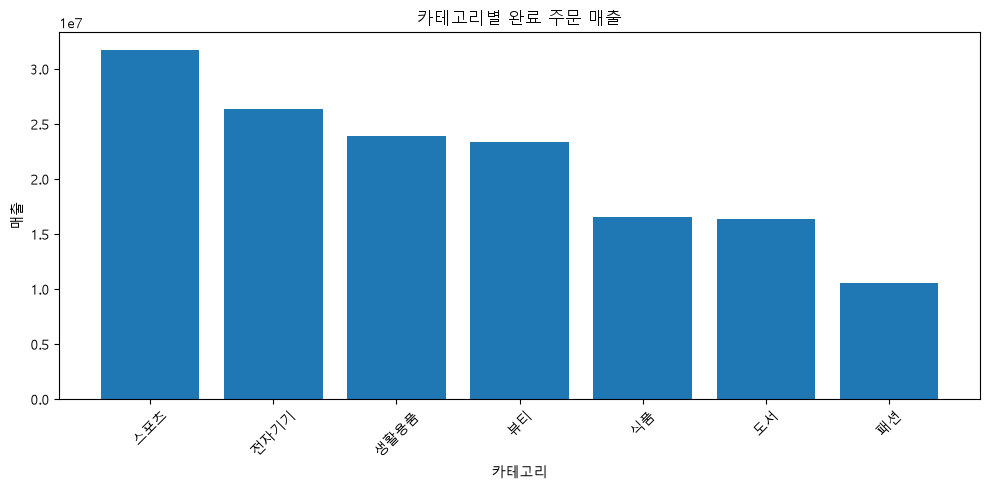

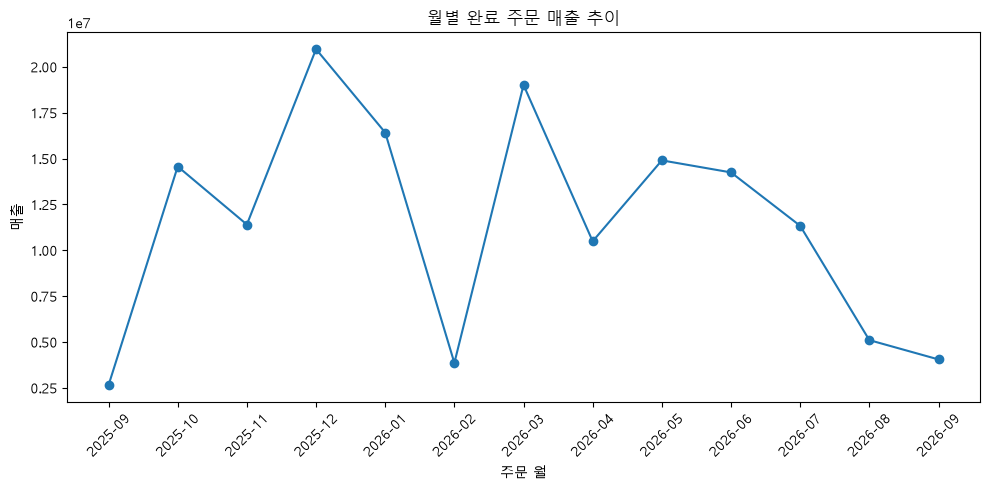

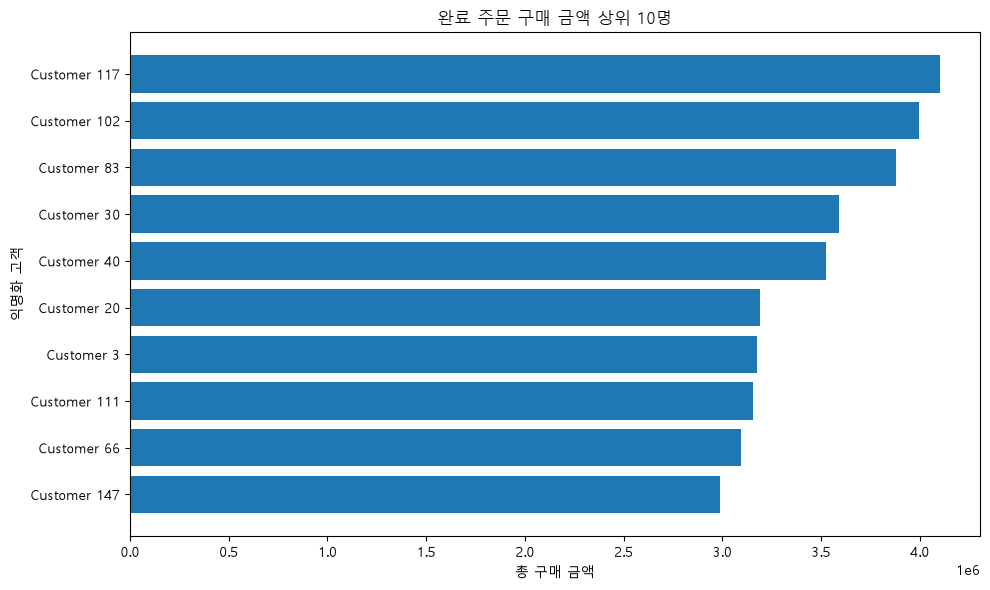

ch08_category_sales.png True 25830
ch08_monthly_sales.png True 81006
ch08_top_customers.png True 45556


In [29]:
saved_figures = create_project_figures(
    analysis_tables,
    FIGURE_DIR,
    show=True,
)

for path in saved_figures:
    print(path.name, path.exists(), path.stat().st_size)


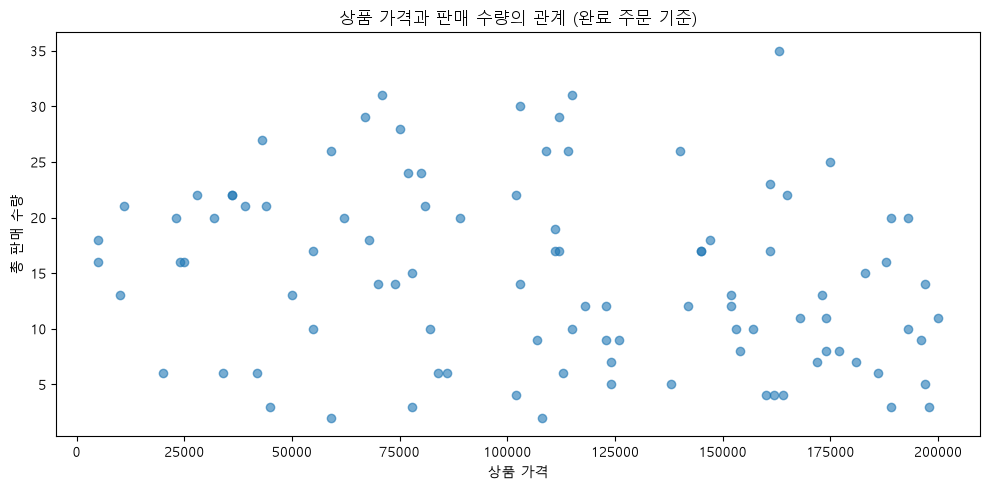

In [30]:
import matplotlib.pyplot as plt

price_qty = (completed_items.groupby(["product_id", "product_name", "category", "price"])
             .agg(total_quantity=("quantity", "sum"))
             .reset_index())

plt.figure(figsize=(10, 5))
plt.scatter(price_qty["price"], price_qty["total_quantity"], alpha=0.6)
plt.title("상품 가격과 판매 수량의 관계 (완료 주문 기준)")
plt.xlabel("상품 가격")
plt.ylabel("총 판매 수량")
plt.tight_layout()
plt.show()

## 10. Markdown 보고서 생성

보고서는 완료 주문 기준, 병합 검증, 익명화 원칙을 명시합니다.


In [31]:
report_text = build_midterm_report(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
)

report_path = REPORT_DIR / 'ch08_midterm_report.md'
report_path.write_text(report_text, encoding='utf-8')

print('보고서 저장:', report_path)
print(report_text[:1500])


보고서 저장: C:\dev\llm-data-analysis-study\reports\ch08_midterm_report.md
# Chapter 8 중간 프로젝트 보고서

## 1. 분석 목적

온라인 쇼핑몰 데이터를 사용해 완료 주문 기준 매출 현황과 고객 구매 패턴을 분석했습니다.

## 2. 분석 기준

- 매출은 `order_status == "completed"`인 주문만 포함했습니다.
- 취소·환불 주문을 포함한 금액은 전체 주문 상세 금액으로 구분했습니다.
- 고객 이름은 결과와 보고서에서 제외하고 익명화 라벨을 사용했습니다.
- 병합은 관계 검증과 행 수·미매칭 확인을 수행했습니다.

## 3. 데이터 개요

```text
    dataset  rows  columns  missing_values  duplicated_rows
  customers   150        6               0                0
   products   100        4               0                0
     orders   300        5               0                0
order_items   764        5               0                0
```

## 4. 전처리 전후 비교

```text
    dataset  rows_raw  columns_raw  rows_processed  columns_processed
  customers       150            6             150                  6
order_items       764            5             764                  6
     orders       300            5             300                  7
   products       100         

## 11. 전체 파이프라인 재실행

단계별 결과를 확인한 뒤에는 같은 함수를 사용하는 전체 파이프라인으로 재현성을 점검합니다.


In [32]:
project_result = run_midterm_project(
    raw_dir=RAW_DIR,
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    figure_dir=FIGURE_DIR,
    show_figures=False,
)

project_result['report_path']


WindowsPath('C:/dev/llm-data-analysis-study/reports/ch08_midterm_report.md')

## 12. 최종 산출물 검증

필수 파일이 존재하고 비어 있지 않은지 확인합니다.


In [33]:
expected_outputs = [
    REPORT_DIR / 'ch08_midterm_report.md',
    REPORT_DIR / 'ch08_dataset_summary.csv',
    REPORT_DIR / 'ch08_preprocessing_comparison.csv',
    REPORT_DIR / 'ch08_key_duplicate_checks.csv',
    REPORT_DIR / 'ch08_relationship_checks.csv',
    REPORT_DIR / 'ch08_merge_checks.csv',
    REPORT_DIR / 'ch08_amount_scope_summary.csv',
    REPORT_DIR / 'ch08_category_sales.csv',
    REPORT_DIR / 'ch08_monthly_sales.csv',
    REPORT_DIR / 'ch08_customer_sales.csv',
    REPORT_DIR / 'ch08_order_status_summary.csv',
    FIGURE_DIR / 'ch08_category_sales.png',
    FIGURE_DIR / 'ch08_monthly_sales.png',
    FIGURE_DIR / 'ch08_top_customers.png',
]

all_outputs_valid = True
for path in expected_outputs:
    valid = path.exists() and path.stat().st_size > 0
    all_outputs_valid &= valid
    print(path.name, 'OK' if valid else 'MISSING OR EMPTY')

print('전체 산출물 검증:', all_outputs_valid)


ch08_midterm_report.md OK
ch08_dataset_summary.csv OK
ch08_preprocessing_comparison.csv OK
ch08_key_duplicate_checks.csv OK
ch08_relationship_checks.csv OK
ch08_merge_checks.csv OK
ch08_amount_scope_summary.csv OK
ch08_category_sales.csv OK
ch08_monthly_sales.csv OK
ch08_customer_sales.csv OK
ch08_order_status_summary.csv OK
ch08_category_sales.png OK
ch08_monthly_sales.png OK
ch08_top_customers.png OK
전체 산출물 검증: True


## 13. 개인정보와 결과 일치 검증

고객 이름이 결과표에 포함되지 않았는지 확인하고, 카테고리 매출 합계와 완료 주문 매출 합계가 일치하는지 확인합니다.


In [34]:
assert 'name' not in customer_sales.columns

completed_total = analysis_tables['completed_order_sales']['line_total'].sum()
category_total = category_sales['total_sales'].sum()
monthly_total = monthly_sales['total_sales'].sum()
customer_total = customer_sales['total_sales'].sum()

print('완료 주문 매출:', completed_total)
print('카테고리 합계:', category_total)
print('월별 합계:', monthly_total)
print('고객별 합계:', customer_total)

assert completed_total == category_total == monthly_total == customer_total
print('결과 합계 일치 검증 완료')


완료 주문 매출: 148990000
카테고리 합계: 148990000
월별 합계: 148990000
고객별 합계: 148990000
결과 합계 일치 검증 완료


## 14. LLM 검토 프롬프트 예시

```text
온라인 쇼핑몰 중간 프로젝트 결과를 검토해 주세요.

분석 기준:
- 매출은 order_status가 completed인 주문만 포함
- 고객 이름은 제외하고 익명화 라벨 사용
- 병합은 validate와 indicator로 검증

검토 항목:
1. 분석 질문과 지표가 연결되어 있는가?
2. 취소·환불 주문이 매출에 포함되지 않았는가?
3. 병합 후 행 증가 또는 미매칭을 확인했는가?
4. 관찰과 원인 가설을 구분했는가?
5. 개인정보가 불필요하게 노출되지 않았는가?
6. Notebook, CSV, 그래프, 보고서의 수치가 일치하는가?

데이터에 없는 원인은 단정하지 말고,
필수 수정과 권장 개선을 구분해 주세요.
```


## 15. 실습 과제

1. 카테고리별 평균 판매 단가를 추가합니다.
2. 월별 취소율과 환불률을 계산합니다.
3. 고객별 최근 구매일과 구매 빈도를 추가합니다.
4. 전체 주문 상세 금액과 완료 주문 매출의 차이를 해석합니다.
5. 결과 합계가 모든 집계표에서 일치하는지 검증 코드를 추가합니다.
6. LLM 활용 내역과 실제 반영 여부를 표로 작성합니다.


In [35]:
# 실습 과제 코드를 아래에 작성하세요.
import pandas as pd

orders = processed_data["orders"]
order_items = processed_data["order_items"]
products = processed_data["products"]

all_items = (
    order_items
    .merge(orders[["order_id", "customer_id", "order_date", "order_status", "order_month"]],
           on="order_id", how="left")
    .merge(products[["product_id", "product_name", "category", "price"]],
           on="product_id", how="left")
)

print(len(all_items), all_items["line_total"].sum())   # 764, 255610000이어야 함

764 255610000


In [36]:
# 과제 1
category_price = (
    completed_items.groupby("category")
    .agg(total_quantity=("quantity", "sum"),
         total_sales=("line_total", "sum"),
         avg_unit_price=("unit_price", "mean"))
    .reset_index()
)
category_price["weighted_avg_price"] = (category_price["total_sales"] / category_price["total_quantity"]).round(0)
category_price["avg_unit_price"] = category_price["avg_unit_price"].round(0)
category_price = category_price.sort_values("total_sales", ascending=False)

display(category_price)

,category,total_quantity,total_sales,avg_unit_price,weighted_avg_price
3,스포츠,295,31743000,109330.0,107603.0
5,전자기기,259,26400000,99577.0,101931.0
2,생활용품,272,23915000,89916.0,87923.0
1,뷰티,223,23383000,102658.0,104857.0
4,식품,133,16573000,126143.0,124609.0
0,도서,149,16389000,114569.0,109993.0
6,패션,111,10587000,98865.0,95378.0


In [37]:
# 과제 2
status_month = (
    orders.groupby(["order_month", "order_status"])["order_id"].nunique()
    .unstack(fill_value=0)
)
status_month["total_orders"] = status_month.sum(axis=1)
status_month["cancel_rate(%)"] = (status_month["cancelled"] / status_month["total_orders"] * 100).round(2)
status_month["refund_rate(%)"] = (status_month["refunded"] / status_month["total_orders"] * 100).round(2)

display(status_month.reset_index())

print(status_month[["completed", "cancelled", "refunded", "total_orders"]].sum())  # 184, 64, 52, 300

order_status,order_month,cancelled,completed,refunded,total_orders,cancel_rate(%),refund_rate(%)
0,2025-09,1,5,2,8,12.50,25.00
1,2025-10,7,16,2,25,28.00,8.00
2,2025-11,4,14,5,23,17.39,21.74
3,2025-12,7,22,1,30,23.33,3.33
4,2026-01,8,19,6,33,24.24,18.18
5,2026-02,4,6,4,14,28.57,28.57
6,2026-03,8,25,5,38,21.05,13.16
7,2026-04,3,16,7,26,11.54,26.92
8,2026-05,9,18,1,28,32.14,3.57
9,2026-06,3,17,4,24,12.50,16.67


order_status
completed       184
cancelled        64
refunded         52
total_orders    300
dtype: int64


In [38]:
# 과제 3
completed_orders = orders[orders["order_status"] == "completed"].copy()
completed_orders["order_date"] = pd.to_datetime(completed_orders["order_date"])

customer_summary = (
    completed_orders.groupby("customer_id")
    .agg(last_purchase_date=("order_date", "max"),
         purchase_count=("order_id", "nunique"))
    .reset_index()
)

order_amount = completed_items.groupby("customer_id")["line_total"].sum().rename("total_amount")
customer_summary = customer_summary.merge(order_amount, on="customer_id", how="left")

display(customer_summary.sort_values("purchase_count", ascending=False).head(10))
print("구매 이력 있는 고객 수:", len(customer_summary), "/ 전체 고객 150명")

,customer_id,last_purchase_date,purchase_count,total_amount
21,30,2026-06-16,5,3590000
76,117,2026-08-12,5,4100000
29,40,2026-07-27,4,3523000
17,24,2026-09-14,4,2419000
51,83,2026-09-09,4,3880000
62,102,2026-05-03,4,3996000
42,66,2026-08-04,4,3093000
68,108,2026-06-18,3,1591000
32,47,2026-06-27,3,1587000
55,90,2026-07-21,3,1831000


구매 이력 있는 고객 수: 100 / 전체 고객 150명


In [39]:
# 과제 4
total_amount = all_items["line_total"].sum()
completed_amount = completed_items["line_total"].sum()

diff_table = (
    all_items.groupby("order_status")
    .agg(detail_rows=("order_item_id", "count"), amount=("line_total", "sum"))
    .reset_index()
)
diff_table["ratio(%)"] = (diff_table["amount"] / total_amount * 100).round(2)
display(diff_table)

print("전체:", total_amount, "완료:", completed_amount, "차이:", total_amount - completed_amount)

,order_status,detail_rows,amount,ratio(%)
0,cancelled,162,62181000,24.33
1,completed,474,148990000,58.29
2,refunded,128,44439000,17.39


전체: 255610000 완료: 148990000 차이: 106620000


In [40]:
# 월별
monthly = (completed_items.groupby("order_month")
           .agg(total_sales=("line_total", "sum"),
                order_count=("order_id", "nunique"))
           .reset_index())

# 카테고리별
category = (completed_items.groupby("category")
            .agg(total_quantity=("quantity", "sum"),
                 total_sales=("line_total", "sum"))
            .reset_index())
category["sales_ratio"] = (category["total_sales"] / category["total_sales"].sum() * 100).round(2)
category = category.sort_values("total_sales", ascending=False)

print(monthly["total_sales"].sum(), category["total_sales"].sum())   # 둘 다 148990000이어야 함

148990000 148990000


In [41]:
# 과제 5
checks = {}

# 완료 기준 집계표들
checks["월별 합계 = 완료 합계"] = monthly["total_sales"].sum() == completed_amount
checks["카테고리 합계 = 완료 합계"] = category["total_sales"].sum() == completed_amount
checks["월별 주문 수 = 완료 주문 184건"] = monthly["order_count"].sum() == 184
checks["카테고리 수량 합 = 완료 수량 합"] = category["total_quantity"].sum() == completed_items["quantity"].sum()
checks["고객별 합계 = 완료 합계"] = customer_summary["total_amount"].sum() == completed_amount

# 전체 기준과의 관계
checks["전체 = 완료 + 취소/환불"] = total_amount == completed_amount + diff_table.loc[diff_table["order_status"] != "completed", "amount"].sum()
checks["월별 상태 건수 합 = 전체 주문 300건"] = status_month["total_orders"].sum() == len(orders)

# line_total 정합성
checks["line_total = quantity × unit_price"] = (all_items["quantity"] * all_items["unit_price"] == all_items["line_total"]).all()

result = pd.DataFrame({"검증 항목": checks.keys(), "통과": checks.values()})
display(result)
assert result["통과"].all(), "일치하지 않는 집계표가 있습니다."

,검증 항목,통과
0,월별 합계 = 완료 합계,True
1,카테고리 합계 = 완료 합계,True
2,월별 주문 수 = 완료 주문 184건,True
3,카테고리 수량 합 = 완료 수량 합,True
4,고객별 합계 = 완료 합계,True
5,전체 = 완료 + 취소/환불,True
6,월별 상태 건수 합 = 전체 주문 300건,True
7,line_total = quantity × unit_price,True


과제 6
| 번호 | 활용 내용 | LLM 제안 | 반영 여부 | 수정 또는 보류 사유 |
|---|---|---|---|---|
| 1 | 결측과 중복 확인 | 테이블별 결측과 중복 요약 함수와 통합 점검 코드 | 반영 | 결측이 0건이어도 보이도록 전체 요약을 출력하게 수정 |
| 2 | 완료 주문 상세 만들기 | orders, order_items, products 병합 후 취소와 환불 제외 | 수정 반영 | 실제 컬럼명인 order_status, line_total, price에 맞춤 |
| 3 | 월별과 카테고리별 집계 | monthly와 category 집계 코드와 합계 검증 | 반영 | 합계 148990000원 일치 확인 |
| 4 | 산점도 생성 | 가격과 총 판매 수량 산점도 코드 | 부분 반영 | 저장 코드는 보류했고 최종 문서에는 월별과 카테고리 그래프를 사용 |
| 5 | 집계표 기준 점검 | 원본 집계값 표가 전체 주문 기준이라는 지적 | 반영 | 표를 완료 기준으로 다시 뽑아 교체 |
| 6 | EDA 결과 문장 작성 | 결과 1, 2, 3 초안과 반복 검증 | 수정 반영 | 그래프 근사값과 전체 기준 값을 표 값으로 교체, 서식 규칙 적용 |
| 7 | 오류 수정 | 모듈 경로 오류의 sys.path 추가 방법 | (실제 적용 여부 기입) | 실행 위치에 따른 오류를 해결하기 위한 제안 |
| 8 | 최종 요약 작성 | 핵심 인사이트, 한계, 다음 분석 제안 | 수정 반영 | 과한 인과 표현을 관찰 표현으로 낮춤 |

## 정리

이번 장에서는 원본 데이터 확인, 전처리, 키 관계 점검, 병합 검증, 완료 주문 기준 매출 계산, 익명화, 시각화, 보고서 생성, 산출물 검증을 하나의 프로젝트로 연결했습니다. 다음 장부터는 이 분석 기반 위에서 머신러닝으로 확장합니다.


# Chapter 08 답안 양식. 작은 데이터 분석 프로젝트 완성하기

> 이 내용을 `chapter08.ipynb`의 Markdown 셀로 작성합니다.

## 제출 정보
- 이름: 황지원
- GitHub ID: Jiwon0712
- 작성일: 2026-10-27
- 최종 Notebook URL: https://github.com/Jiwon0712/llm-data-analysis-study/blob/main//chapter08/chapter08.ipynb

### 분석 질문
월별 매출은 어떻게 변하는가?
카테고리별 매출 비중은 어떻게 다른가?
상품 가격이 높을수록 판매 수량이 줄어드는가? 
### 분석 범위
- 대상 데이터: customers, products, orders, order_items
- 분석 기준: 완료 주문 상세(completed_order_items) 474건, 148990000원
- 제외 대상: 취소/환불 주문 상세 290건, 106620000원
- 결측, 중복, PK/FK 점검을 마친 전처리 데이터(processed)를 사용
### 사용할 데이터와 지표
- 월별 매출 추이: orders(주문 일자/주문 상태) + order_items(금액) -> 월별 매출 합계 (선 그래프)
- 카테고리별 매출 비중: order_items + products(카테고리) -> 카테고리별 매출, 비중(%) (막대 그래프)
- 가격과 판매 수량 관계: products(가격) + order_items(수량) -> 상품별 가격, 총 판매 수량 (산점도)
- 결합 키: order_id, product_id 
### 완료 기준
- 세 질문 각각에 대해 선택한 그래프가 그려져 있다.
- 모든 그래프가 완료 주문 기준으로 일관되게 계산되었고, 합계가 148990000원과 일치한다.
- 각 그래프마다 결과 해석이 한두 문장으로 정리되어 있다.

## 2. 입력 데이터 검증
- 사용 파일: customers_clean.csv, order_items_clean.csv, orders_clean.csv, products_clean.csv
- shape:customers(150, 6), order_items(100, 4), orders(300, 7), products(764, 6)
- 결측/중복 핵심 결과: 4개 데이터 모두 결측 셀 0건, 전체 행 중복 0건, 식별 키(customer_id, product_id, order_id, order_item_id) 중복 0건으로 확인됨. 전처리 후 행 수는 원본과 동일하게 유지됨.
- PK/FK 확인: 4개 테이블의 PK 중복이 없고, FK 3건(orders.customer_id -> customers, order_items.order_id -> orders, order_items.product_id -> products) 모두 기준 테이블에 존재하지 않는 값이 0건임. 병합 시에도 order_id -> orders(764건), product_id -> products(474건), customer_id -> customers(100건) 모두 병합 전후 행 수가 유지되고 unmatched가 0건이라 병합으로 인해 행이 늘거나 줄지 않았음.
- 금액 범위 정의: 전체 주문 상세 764건 255610000원 중, 완료 주문 상세 474건 148990000원을 분석 기준으로 사용하고, 취소/환불 주문 상세 290건 106620000원은 제외함. (금액 단위는 별도로 제시되어 있지 않지만, 합리적인 판단 하에 "원"으로 표기함)

![입력 데이터 검증](images/step02_data_validation.png)

### 나의 해석과 판단
- 4개 테이블 모두 결측, 전체 행 중복, 식별 키 중복이 없고 FK 3건도 모두 정상이라, 별도의 보정이나 삭제 없이 전처리 데이터를 그대로 분석에 사용해도 된다고 판단했다.
- 병합 전후 행 수가 유지되고 unmatched가 0건이므로, 병합 때문에 매출이 중복 집계되거나 누락될 위험은 낮다고 본다.
- 전체 주문 상세 764건 중 290건(약 38%), 금액으로는 255610000 중 106620000원(약 42%)이 취소/환불이라 비중이 작지 않다. 전체 기준과 완료 기준의 매출 차이가 크므로, 이후 모든 분석은 완료 주문 기준(474건, 148990000원)으로 통일한다.

### 한계와 추가 확인 사항
- 결측은 `isna()` 기준으로만 확인했다. 빈 문자열이나 N/A 같은 placeholder 값, 이상치는 별도로 확인하지 않았다.
- 금액 단위가 데이터에 명시되어 있지 않아 "원"으로 가정했다. 실제 통화 단위를 확인해야 한다.
- 취소/환불 상태 값의 정확한 정의를 확인하지 못했고, 제외 기준이 분석 목적에 맞는지 추가 검토가 필요하다.
- 주문 일자의 범위와 기간 정보를 아직 확인하지 않았으므로, 월별 추이 분석 전에 데이터 기간과 누락된 달이 없는지 살펴봐야 한다.

## 3. 핵심 EDA 결과
### 결과 1
- 수치/표: 월별 완료 주문 매출과 주문 수를 2025-09부터 2026-09까지 13개월 동안 집계했고 합계는 148990000원, 184건이다. 최고 매출은 2025-12의 20963000원(22건)이고 그다음이 2026-03의 19010000원, 2026-01의 16416000원이다. 최저 매출은 2025-09의 2650000원, 2026-02의 3861000원, 2026-09의 4051000원이다.
- 결과 관찰: 2025-10부터 2026-07까지는 월 380만 원에서 2100만 원 사이에서 크게 오르내린다. 2025-12 정점 20963000원 이후 2026-02에 3861000원으로 약 82% 급감했고, 2026-03에 19010000원으로 회복했다. 2026-04에 다시 10490000원으로 줄었다가 2026-05와 2026-06에는 1400만 원대를 유지했고, 2026-07부터 11333000원, 5103000원, 4051000원으로 계속 낮아졌다. 매출이 높은 달은 주문 수도 많아서 2026-03은 25건, 2025-12는 22건이고 두 값이 같은 경향으로 움직인다. 평균 주문 금액은 약 53만 원에서 102만 원 범위다.
- 나의 해석과 판단: 2025-09, 2026-08, 2026-09는 주문이 5건뿐이라 월 전체가 아니라 일부 기간만 수집됐을 가능성을 먼저 확인해야 하고, 실제 매출 감소로 단정하지 않는다. 2026-02는 6건이라 급감 원인을 따로 점검해야 한다. 12월과 3월이 높은 것은 해당 시기 수요 영향일 수 있으나 13개월치로는 단정할 수 없다.
- 업무적 의미: 매출 변동은 주로 주문 건수 차이에서 나오고 평균 주문 금액은 상대적으로 안정적이다. 따라서 매출을 높이려면 객단가보다 주문 건수를 늘리는 쪽이 효과적이며, 성수기인 2025-12와 2026-03, 비수기인 2026-02와 2026-04, 2026-08과 2026-09를 나눠 재고와 프로모션을 계획할 필요가 있다.
- 한계: 약 13개월치라 같은 달의 연도 간 비교와 계절성 판단이 어렵다. 양 끝 달과 최근 달은 집계 기간이 불완전할 수 있다. 완료 주문만 기준이라 전체 300건 중 완료 184건이 61.33%이고, 취소 64건이 21.33%, 환불 52건이 17.33%인 나머지는 반영되지 않았다.

### 결과 2
- 수치/표: 카테고리별 완료 주문 매출과 비중이며 합계는 148990000원이다. 스포츠는 31743000원, 21.31%, 295개이고 전자기기는 26400000원, 17.72%, 259개이다. 생활용품은 23915000원, 16.05%, 272개이고 뷰티는 23383000원, 15.69%, 223개이다. 식품은 16573000원, 11.12%, 133개이고 도서는 16389000원, 11.00%, 149개이며 패션은 10587000원, 7.11%, 111개이다.
- 결과 관찰: 스포츠가 21.31%로 1위이고 패션이 7.11%로 최하위이며, 두 카테고리의 매출 차이는 약 3배다. 상위 4개인 스포츠, 전자기기, 생활용품, 뷰티가 전체의 약 70.8%를 차지하고, 식품과 도서는 각각 약 11%로 거의 같은 수준이다. 수량은 스포츠 295개, 생활용품 272개, 전자기기 259개 순이라 매출 순위와 다르다. 생활용품은 수량 2위지만 매출은 3위이고, 전자기기는 수량 3위지만 매출은 2위다.
- 나의 해석과 판단: 한 카테고리에 극단적으로 쏠리지는 않지만 상위 4개와 하위 3개 사이에 구간 차이가 뚜렷하다고 판단한다. 개당 매출은 매출을 수량으로 나눈 값으로, 식품 약 12.5만 원, 도서 약 11만 원, 스포츠 약 10.8만 원, 뷰티 약 10.5만 원, 전자기기 약 10.2만 원, 패션 약 9.5만 원, 생활용품 약 8.8만 원이다. 수량이 많다고 매출이 큰 것은 아니다.
- 업무적 의미: 스포츠와 전자기기를 재고와 마케팅의 우선 대상으로 두고, 하위 3개인 식품, 도서, 패션은 상품 구성과 가격 정책을 점검할 수 있다. 생활용품은 판매 수량이 많은 만큼 단가나 구성 개선 여지가 있다.
- 한계: 매출 금액과 수량만 비교했기 때문에 카테고리별 상품 수와 가격대 차이는 반영되지 않았다. 상품이 많은 카테고리가 단순히 매출도 클 수 있다. 완료 주문만 포함하였기 때문에 취소/환불된 주문에서 얻을 수 있는 정보는 없다.

### 결과 3
- 수치/표: 완료 주문에서 판매된 상품 98개의 가격은 평균 110622원, 중앙값 112000원, 범위 5000원에서 200000원이다. 총 판매 수량은 평균 14.7개, 중앙값 14개, 범위 2개에서 35개다. 피어슨 상관계수는 r = -0.239이다. 판매 수량 상위 5개와 하위 5개 상품 표를 별도로 제시한다.
- 결과 관찰: 상관계수가 약한 음의 값이라 가격이 높을수록 판매 수량이 약간 줄어드는 경향은 있으나 그 정도는 약하다. 결정계수는 약 0.057이라 판매 수량 변동의 약 5.7%만 가격으로 설명된다. 수량 상위 5개의 가격은 71000원에서 163000원 사이로 섞여 있고, 스포츠 상품 041은 163000원에 35개, 전자기기 상품 077은 71000원에 31개다. 하위 5개도 45000원에서 189000원 사이로 가격대가 섞여 있고, 그중 가장 비싼 상품은 스포츠 상품 008로 189000원에 3개다.
- 나의 해석과 판단: 가격이 높을수록 판매 수량이 줄어든다는 방향은 맞지만 관계가 약해서, 가격이 판매 수량을 결정하는 주된 요인이라고 보기는 어렵다고 판단한다. 같은 가격대에서도 판매 수량 차이가 크기 때문이다.
- 업무적 의미: 가격 인하가 판매량 증가에 일부 도움이 될 수는 있지만 효과가 크지 않을 가능성이 높다. 카테고리, 상품 노출, 프로모션 등 다른 요인을 함께 검토해야 한다.
- 한계: 상관계수는 선형 관계만 측정하며 인과관계를 뜻하지 않는다. 카테고리별 차이와 판매 기간 차이가 반영되지 않았고, 완료 주문만 기준이라 한 번도 팔리지 않은 상품 2개는 제외됐다.

## 4. 대표 시각화
![대표 그래프 1](images/graph01.png)
![대표 그래프 2](images/graph02.png)

### 그래프 선택 이유
- 월별 완료 주문 매출 선 그래프는 시간 순서에 따른 매출 추세를 한눈에 보기 좋아서 골랐다. 2025-12 정점, 2026-02 급감, 2026-03 회복, 2026-07 이후 하락 같은 흐름이 선의 모양으로 바로 드러난다.
- 카테고리별 완료 주문 매출 막대 그래프는 카테고리 사이의 크기 비교가 쉬워서 골랐다. 스포츠가 31743000로 가장 크고 패션이 10587000로 가장 작은데, 이 격차와 순위가 막대 길이로 분명하게 보인다.

### 그래프와 원본 집계값 일치 여부
- 월별 그래프는 원본 집계값과 일치한다. 13개월 매출 합계가 148990000원이고 주문 수 합계가 184건으로, 완료 주문 기준 총액 및 주문 상태 표의 completed 184건과 맞다. 최고점 2025-12의 20963000원과 최저점 2025-09의 2650000원도 그래프의 점 위치와 같다.
- 카테고리 그래프도 원본 집계값과 일치한다. 7개 카테고리 매출 합계가 148990000원이고 매출 순서가 스포츠, 전자기기, 생활용품, 뷰티, 식품, 도서, 패션으로 막대 순서와 같다.
- 두 그래프의 총액이 같은 148990000원이므로 집계 기준이 서로 섞이지 않았다.
- 그래프의 세로축이 1e7 단위로 표시되어 눈금만으로는 정확한 금액을 읽기 어렵기 때문에, 정확한 수치는 원본 집계값 표를 기준으로 삼는다.

### 그래프만으로 말할 수 없는 것
- 월별 하락과 급감의 원인은 그래프만으로 알 수 없다. 2025-09, 2026-08, 2026-09처럼 주문이 5건뿐인 달이 실제 매출 감소인지 데이터 수집 기간이 짧았기 때문인지 구분할 수 없다.
- 12월과 3월이 높은 것이 계절성인지 프로모션 효과인지 단정할 수 없다. 13개월치라 같은 달의 연도 간 비교가 불가능하다.
- 카테고리 그래프는 매출 금액만 보여 주므로 카테고리별 상품 수, 가격대, 판매 수량 차이의 영향은 알 수 없다. 상품이 많은 카테고리가 단순히 매출도 클 수 있다.
- 취소 64건과 환불 52건은 제외된 값이라 전체 주문 기준의 매출이나 취소 환불의 영향은 그래프로 알 수 없다.
- 고객별 구매 패턴, 재구매 여부, 결제 수단별 차이는 이 그래프에 담겨 있지 않다.
- 그래프 사이의 인과관계는 판단할 수 없고, 관찰된 흐름은 추가 확인이 필요한 가설로만 쓸 수 있다.

## 5. LLM 활용 기록
- 사용 여부: 사용함
- 사용 목적: 데이터 품질 점검 코드(결측/중복)를 작성하고, 월별 매출, 카테고리별 매출, 가격과 판매 수량 산점도를 완료 주문 기준으로 다시 집계하고 그리는 코드를 만들기 위해 사용했다.
- Prompt 요약: 전처리된 4개 테이블의 결측과 중복을 확인하는 코드를 요청했다. 결측이 0건일 때도 눈에 보이게 출력하는 방법을 묻고, 결측과 중복을 한 번에 요약하는 통합 코드를 요청했다. 이후 완료 주문 상세 데이터프레임을 만드는 방법과 컬럼명 대응을 물었고, 그 결과로 월별과 카테고리별 집계 코드와 산점도 생성 코드를 요청했다.
- 제안 요약: 테이블별 결측 셀과 중복 행과 식별 키 중복을 한 표로 요약하고 결론 메시지를 출력하는 함수를 제안받았다. 취소와 환불을 제외한 completed_items를 병합으로 만들고 금액 합계가 148990000원, 행 수가 474건이 되는지 검증하라는 제안을 받았다. 이를 바탕으로 월별 매출, 카테고리별 매출과 비중, 가격과 총 판매 수량 집계 코드와 산점도 코드가 제시됐다. 또 노트북의 원본 집계값 표가 전체 주문 기준이라 완료 기준 그래프와 맞지 않는다는 지적을 받았다.
- 반영/수정/보류: 결측과 중복 확인 코드와 completed_items 생성 코드는 실제 컬럼명인 order_status, line_total, price에 맞게 수정해서 반영했다. 월별과 카테고리 집계와 산점도 코드도 반영했고, 저장 코드는 보류했다. 집계표를 완료 기준으로 다시 뽑아 문서의 원본 집계값을 교체했다. 그래프 선택은 질문과 일치하는 월별과 카테고리 그래프 2개를 쓰기로 하고 산점도는 제외했다. 그래프에서 읽은 근사값이나 전체 기준 값으로 쓰인 문장은 실제 표 값으로 고쳤다.
- 사람이 검증한 근거: 월별 매출 13개월 합과 카테고리 매출 7개 합이 모두 148990000로 완료 주문 기준 총액과 일치함을 직접 확인했다. 월별 주문 수 합 184건이 주문 상태 표의 completed 184건과 같고, 결측과 중복과 PK, FK 점검 결과가 0건임을 노트북 출력으로 확인했다. 그래프의 점과 막대 위치를 표 값과 눈으로 대조했고, LLM이 처음 쓴 틀린 내용은 표를 보고 바로잡았다.

## 6. 프로젝트 재현 확인
- `scripts/run_midterm_project.py` 실행 여부:
- 재실행 결과:
- Notebook과 핵심 수치 일치 여부:

![재실행 결과](images/step06_reproduce.png)

### 나의 해석과 판단
재실행 가능한 프로젝트가 중요한 이유는 분석 결과를 믿고 쓸 수 있는 근거가 되기 때문이다. 이번 작업에서도 처음에는 노트북의 원본 집계값 표가 전체 주문 기준이고 그래프는 완료 주문 기준이라 숫자가 서로 맞지 않는 문제가 있었다. 이런 기준 불일치는 어느 셀을 어떤 순서로 실행했는지에 따라 결과가 달라질 때 생긴다. 전처리부터 집계와 그래프 생성까지 한 번에 다시 실행되는 스크립트가 있으면 같은 입력에서 항상 같은 표와 그래프가 나오므로, 기준이 섞일 여지가 줄어든다.

또한 재실행이 가능하면 검증이 쉬워진다. 이번 분석에서는 월별 매출과 카테고리 매출의 합계가 모두 148990000원인지, 주문 수 합계가 완료 184건과 같은지를 코드로 바로 확인할 수 있었다. 데이터가 바뀌거나 분석 기준이 수정되어도 스크립트를 다시 돌리면 표와 그래프와 문서의 숫자를 같은 기준으로 갱신할 수 있다. 노트북에서 손으로 값을 옮겨 적는 방식은 누락과 오타가 생기기 쉽지만, 재실행 구조에서는 이런 오류를 줄일 수 있다.

마지막으로 다른 사람이 내 결과를 확인하고 이어서 작업할 수 있다는 점도 중요하다. 폴더 구조와 실행 명령이 정리되어 있으면 처음 보는 사람도 같은 결과를 재현할 수 있고, 그래야 분석이 개인의 작업 기록에서 팀이 공유할 수 있는 자산이 된다. 실행 위치에 따라 모듈을 찾지 못하는 오류를 직접 겪어 보니, 경로와 실행 방법까지 문서화되어야 진짜 재실행 가능한 프로젝트라고 판단한다.

## 7. 최종 프로젝트 요약
### 핵심 인사이트 3개
1. 월별 완료 주문 매출은 한 방향으로 늘거나 줄지 않고 크게 오르내린다. 2025-12에 20963000원으로 정점이었고, 2026-02에 3861000원으로 급감했다가 2026-03에 19010000원으로 회복했다. 월별 주문 수는 5건에서 25건으로 약 5배 차이가 나고 평균 주문 금액은 약 53만 원에서 102만 원으로 약 2배 차이가 나서, 매출 변동은 평균 주문 금액보다 주문 수의 영향을 더 크게 받는 것으로 보인다.
2. 카테고리별 매출은 스포츠가 31743000원으로 21.31%를 차지해 가장 크고, 패션이 10587000원으로 7.11%를 차지해 가장 작다. 스포츠, 전자기기, 생활용품, 뷰티 4개가 전체의 약 70.8%를 차지해 상위 4개와 하위 3개 사이에 구간 차이가 뚜렷하다.
3. 전체 주문 300건 중 완료 주문은 184건으로 61.33%이고, 취소 64건과 환불 52건이 나머지 38.67%다. 금액으로는 주문 상세 764건의 합계 255610000원 중 완료 상세 474건이 148990000원이고, 취소와 환불 상세 290건이 106620000원이다. 어느 기준을 쓰느냐에 따라 매출 규모가 크게 달라진다.

### 가장 중요한 업무적 의미
매출 변동은 평균 주문 금액보다 주문 건수에 더 크게 좌우되므로, 매출 관리의 우선 지표는 월별 주문 건수로 두는 것이 적절하다. 카테고리 면에서는 매출 비중이 큰 스포츠와 전자기기를 재고와 마케팅의 우선 대상으로 두고, 매출이 낮은 식품, 도서, 패션은 상품 구성과 가격 정책을 점검할 수 있다. 또한 취소와 환불이 전체 주문의 38.67%로 비중이 작지 않아, 매출을 볼 때 완료 기준과 함께 관리해야 한다.

### 현재 분석의 한계
- 데이터가 약 13개월치라 같은 달의 연도 간 비교가 어렵고 계절성을 단정할 수 없다.
- 2025-09, 2026-08, 2026-09는 주문이 5건뿐이고 2026-02도 6건이라, 실제 감소인지 수집 기간 문제인지 구분하지 못했다.
- 완료 주문만 기준이라 취소와 환불의 영향은 반영되지 않았다.
- 카테고리 비교에는 상품 수와 가격대 차이가 반영되지 않았다.
- 가격과 판매 수량의 상관계수는 -0.239로 약한 관계였고, 상관은 인과를 뜻하지 않는다.
- 금액 단위가 데이터에 명시되어 있지 않아 원으로 가정했다.

### 다음 분석 제안
1. 주문 데이터의 시작일과 종료일을 확인하고 월별 주문 수를 비교해, 주문이 5건뿐인 달이 수집 기간 문제인지 실제 감소인지 구분한다.
2. 취소와 환불 주문을 카테고리별, 월별, 결제 수단별로 나눠 비율이 높은 곳을 찾고, 그 결과로 원인 가설을 세운다.
3. 카테고리별 상품 수와 가격대를 함께 보고, 가격과 판매 수량의 관계를 카테고리별로 나눠 다시 확인한다.

## 최종 체크
- [x] 질문→데이터→EDA→시각화→해석이 연결됩니다.
- [x] 핵심 결과에 근거가 있습니다.
- [x] 한계와 다음 분석을 작성했습니다.
- [x] 재실행 가능성을 확인했습니다.
- [x] 최종 Notebook URL을 제출합니다.